In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [45]:
df = sns.load_dataset('flights')
print(df.head())

   year month  passengers
0  1949   Jan         112
1  1949   Feb         118
2  1949   Mar         132
3  1949   Apr         129
4  1949   May         121


In [46]:
df['yearMonth'] = pd.to_datetime("01-"+df['month'].astype(str) + "-" + df['year'].astype(str))
df.set_index('yearMonth', inplace=True)

In [47]:
airP = df[['passengers']].copy(deep=True)

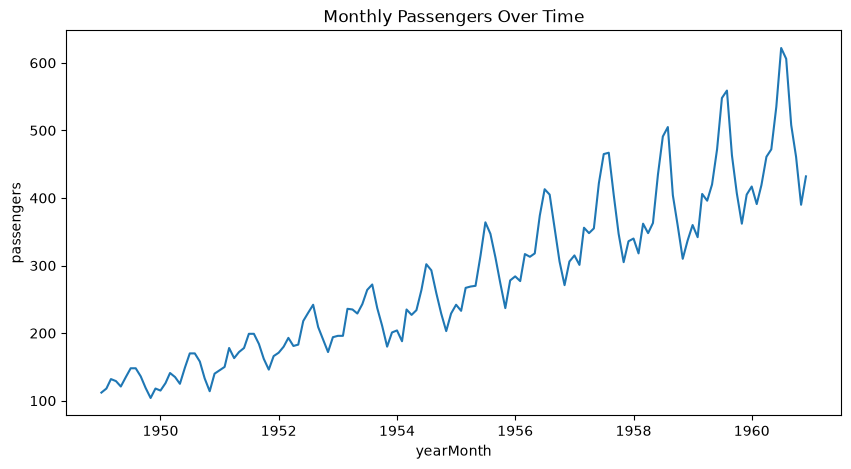

In [48]:
plt.figure(figsize=(10,5))
sns.lineplot(x=airP.index, y=airP['passengers'])
plt.title("Monthly Passengers Over Time")
plt.show()

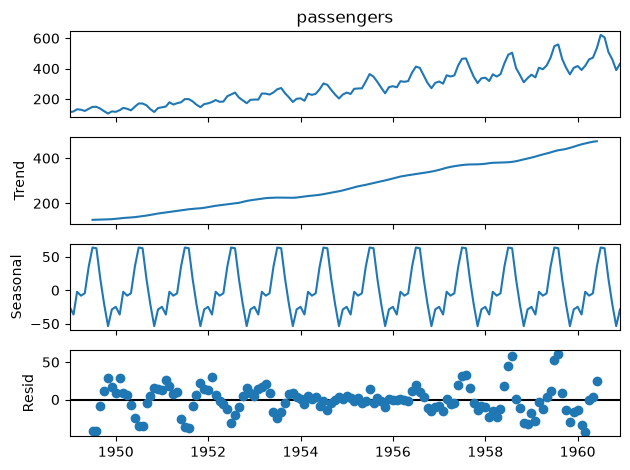

In [49]:
#Decompose to check trend and seasonality
decomposition = seasonal_decompose(airP.passengers,period=12)
decomposition.plot()
plt.show()

In [50]:
# Stationary check
def test_stationary(dataframe, var, window=12):
    dataframe['rollMean'] = dataframe[var].rolling(window=window).mean()
    dataframe['rollStd'] = dataframe[var].rolling(window=window).std()
    adf_result = adfuller(dataframe[var])
    p_value = adf_result[1]

    print(f"ADF p-value : {p_value:.4f}")

    if p_value < 0.05:
        print("The time series is stationary (Reject H0)")
    else:
        print("The time series is not stationary (Failed to reject H0)")

    sns.lineplot(x=dataframe.index, y=dataframe[var], label="Original")
    sns.lineplot(x=dataframe.index, y=dataframe["rollMean"], label="Rolling Mean")
    sns.lineplot(x=dataframe.index, y=dataframe["rollStd"], label="Rolling Std")
    plt.title("Rolling Statistics")
    plt.show()

ADF p-value : 0.9919
The time series is not stationary (Failed to reject H0)


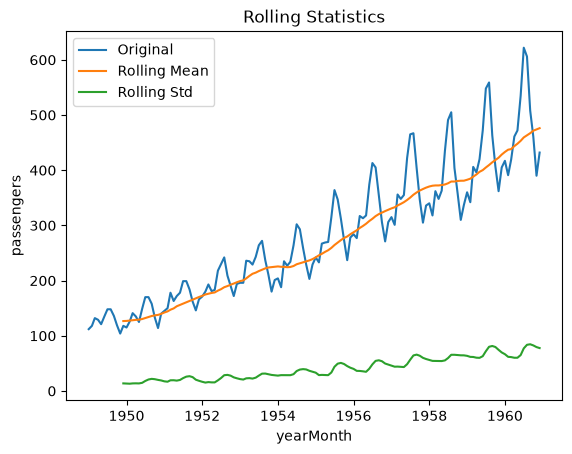

In [51]:
test_stationary(airP, 'passengers')



ADF p-value : 0.0707
The time series is not stationary (Failed to reject H0)


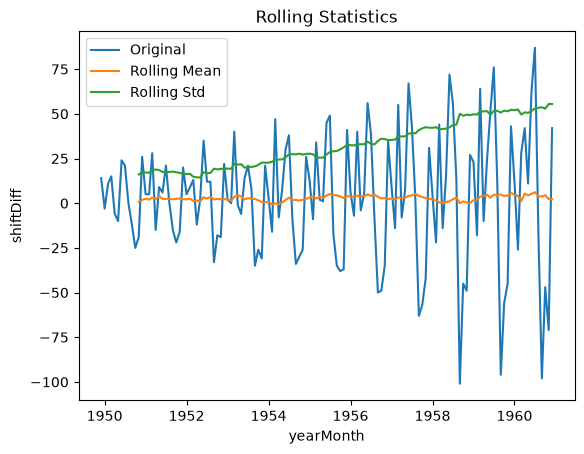

In [52]:
#Not stationary try with diff(1)
airP['shift']=airP.passengers.shift(1)
airP['shiftDiff']=airP['passengers']-airP["shift"]
airP.head(20)
test_stationary(airP.dropna(),'shiftDiff')


ADF p-value : 0.0397
The time series is stationary (Reject H0)


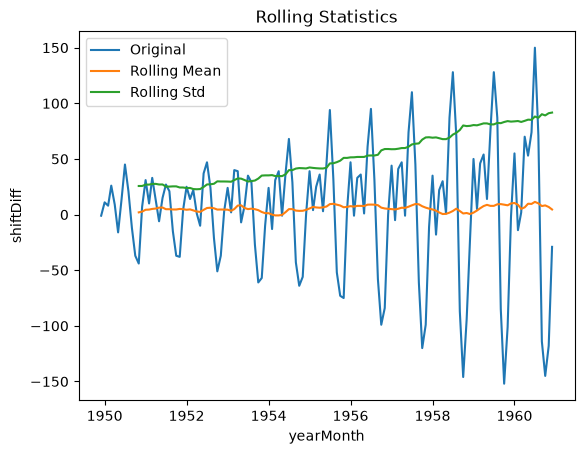

In [53]:
airP['shift'] = airP.passengers.shift(2)
airP['shiftDiff']=airP['passengers']-airP["shift"]
airP.head(20)
test_stationary(airP.dropna(),'shiftDiff')


In [54]:
airP['seconDiff'] = airP["passengers"].diff(2)
airP["Diff12"] = airP["passengers"].diff(12)

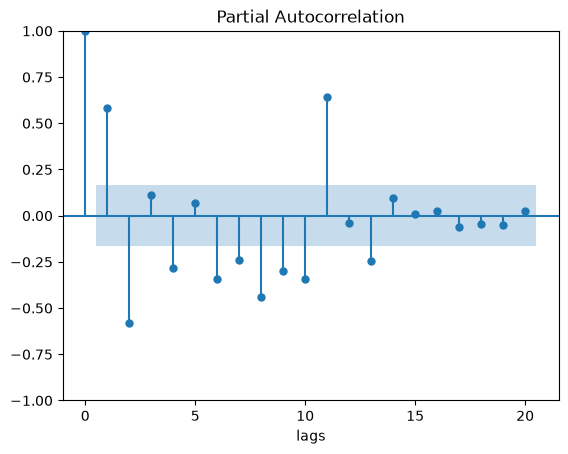

In [55]:
plot_pacf(airP['seconDiff'].dropna(),lags=20) # p
plt.xlabel('lags')
plt.show()

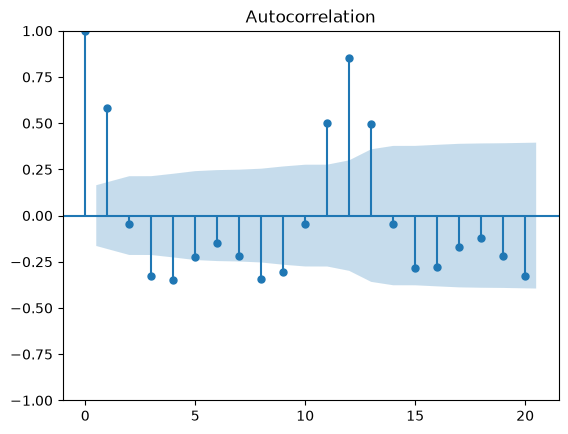

In [56]:
plot_acf(airP['seconDiff'].dropna(),lags=20)
plt.show()

In [57]:
train_size = int(len(airP)*0.7)
train = airP.iloc[:train_size]
test = airP.iloc[train_size:]

In [58]:
# ARIMA Model

model_arima = ARIMA(train['passengers'],order=(1,2,1))
model_arima_fit = model_arima.fit()
arima_pred = model_arima_fit.predict(start=len(train),end=len(airP)-1)

d:\notebook\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
d:\notebook\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
d:\notebook\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [59]:
# Add ARIMA pred to df
airP['arimaPred'] = np.nan
airP.iloc[train_size:,airP.columns.get_loc('arimaPred')] = arima_pred.values
airP.head()

,passengers,rollMean,rollStd,shift,shiftDiff,seconDiff,Diff12,arimaPred
yearMonth,,,,,,,,
1949-01-01,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-02-01,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-03-01,132,NaN,NaN,112.0,20.0,20.0,NaN,NaN
1949-04-01,129,NaN,NaN,118.0,11.0,11.0,NaN,NaN
1949-05-01,121,NaN,NaN,132.0,-11.0,-11.0,NaN,NaN


In [60]:
airP.tail()

,passengers,rollMean,rollStd,shift,shiftDiff,seconDiff,Diff12,arimaPred
yearMonth,,,,,,,,
1960-08-01,606,463.333333,83.630500,535.0,71.0,71.0,47.0,439.708765
1960-09-01,508,467.083333,84.617276,622.0,-114.0,-114.0,45.0,442.074511
1960-10-01,461,471.583333,82.541954,606.0,-145.0,-145.0,54.0,444.440256
1960-11-01,390,473.916667,79.502382,508.0,-118.0,-118.0,28.0,446.806002
1960-12-01,432,476.166667,77.737125,461.0,-29.0,-29.0,27.0,449.171747


In [61]:
airP['diff_combined'] = airP['passengers'].diff(2).diff(12)

<function matplotlib.pyplot.show(close=None, block=None)>

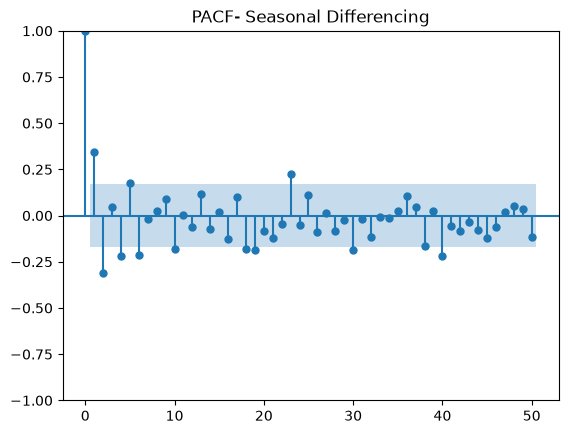

In [62]:
plot_pacf(airP['diff_combined'].dropna(), lags=50)
plt.title("PACF- Seasonal Differencing")
plt.show

In [ ]:
model_sarimax = SARIMAX(train['passengers'], order=(1,2,1),seasonal_order=(1,2,1,12))
model_sarimax_fit = model_sarimax.fit()
model_sarimax = model_sarimax_fit.predict(start=len)

In [64]:
import numpy as np
airP['sarimaxPred'] = np.nan
airP.iloc[train_size:, airP.columns.get_loc('sarimaxPred')] = sarimax_pred.values
print(airP.tail(20))

NameError: name 'sarimax_pred' is not defined

In [ ]:
# 